## 1. Project overview

Supervised undergraduate research by Seyedamir Rahmani, IUST; supervisor Mahboubeh Molavi-Arabshahi. Adapted from Yang and Xing (2021), DOI 10.3390/atmos12101318. Five fixed configurations reconstruct withheld ERA5 grid temperatures.

## 2. Imports and experiment configuration

MAP_MODE can be none (evaluation only), dem_independent (four maps without elevation), or full (all five maps using documented SRTM). The numerical settings are unchanged.

In [1]:
import json
import pandas as pd
import analysis as experiment
MAP_MODE = 'full'
assert MAP_MODE in ('none', 'dem_independent', 'full')
cfg = experiment.configuration()
experiment.output_dirs(cfg)

## 3. Data acquisition requirements

Follow data/README.md for the CDS request and authorized GADM acquisition. Evaluation-only mode needs only data.nc and gadm41_IRN_1.json. Full maps use the documented SRTM GL1 CSV and generated provenance sidecar; data were acquired via the public OpenTopography mirror. The historical uncertain CSV is never substituted.

## 4. Data loading and preprocessing

T_C = T_K - 273.15. Monthly timestamps, units, missing values, unique spatial-month records and coverage are checked. Annual/MAM/JJA/SON/pooled DJF retain equal monthly weights.

In [2]:
periods, boundary, dem, audit = experiment.load_data(cfg, require_dem=(MAP_MODE == 'full'))
pd.DataFrame({k: len(v) for k,v in periods.items()}, index=['locations'])

,annual,spring,summer,fall,winter
locations,23,23,23,23,23


## 5. Geographical and elevation data processing

Longitude/latitude is projected to EPSG:32639 in km. ERA5 z/9.80665 is used in folds. SRTM EGM96 orthometric heights are for IDW target maps only; they are not identical to geopotential heights. prepare_dem.py samples the existing 0.005° point grid bilinearly, preserves its row order, and rejects missing support. No historical DEM-dependent image is embedded here.

## 6. Interpolation methods

One dispatcher preserves all five verified configurations. IDW: power 2 and fixed lapse correction. Raw-kernel RBF: thin-plate and multiquadric, zero smoothing and no polynomial tail. OK: spherical covariance, 55.5 km range. EBK-inspired local kriging: bounded variogram-residual pseudo-target, 15 neighbors, 150 MH iterations with 75 burn-in, 30 inverse-transformed model predictions averaged. No calibrated posterior or predictive uncertainty is claimed.

In [3]:
cfg['methods']

['IDW',
 'RBF Thin-Plate Spline',
 'RBF Multiquadric',
 'Ordinary Kriging',
 'EBK-inspired local kriging']

## 7. Numerical validation

Run mathematical checks, withheld-temperature exclusion, parallel reproducibility, DEM-free CLI regression and synthetic raster tests. Synthetic raster fixtures are not experimental elevation data.

In [4]:
import unittest
suite = unittest.defaultTestLoader.discover(str(experiment.ROOT), pattern='test_*.py')
check = unittest.TextTestRunner(verbosity=1).run(suite)
assert check.wasSuccessful()

.

.

.

.

.

.

... (7 outputs left out)

.

.

.

----------------------------------------------------------------------
Ran 16 tests in 21.141s

OK


## 8. Annual and seasonal temperature reconstruction

The next execution uses MAP_MODE. none skips maps without reading any DEM. dem_independent regenerates four map configurations. full requires the documented SRTM replacement. Fine output spacing is display sampling, not increased observational resolution.

## 9. Leave-one-out cross-validation

The same 23 locations are withheld for each method and period. Transformations and variograms use training temperatures only. Failure records are retained and invalidate affected aggregates.

In [5]:
predictions, aggregate, ranking = experiment.run(maps=(MAP_MODE != 'none'), dem_independent=(MAP_MODE == 'dem_independent'))
predictions.groupby(['period','method']).size()

Maps complete: annual


Maps complete: spring


Maps complete: summer


Maps complete: fall


Maps complete: winter


period  method                    
annual  EBK-inspired local kriging    23
        IDW                           23
        Ordinary Kriging              23
        RBF Multiquadric              23
        RBF Thin-Plate Spline         23
fall    EBK-inspired local kriging    23
        IDW                           23
        Ordinary Kriging              23
        RBF Multiquadric              23
        RBF Thin-Plate Spline         23
spring  EBK-inspired local kriging    23
        IDW                           23
        Ordinary Kriging              23
        RBF Multiquadric              23
        RBF Thin-Plate Spline         23
summer  EBK-inspired local kriging    23
        IDW                           23
        Ordinary Kriging              23
        RBF Multiquadric              23
        RBF Thin-Plate Spline         23
winter  EBK-inspired local kriging    23
        IDW                           23
        Ordinary Kriging              23
        RBF Multiquadr

## 10. Statistical evaluation

MAE = mean absolute error; RMSE = sqrt(MSE); NSE = 1-SSE/SST; Spearman correlates average ranks. Undefined cases remain undefined. Historical Celsius MAPE/SMAPE are scale-origin dependent. Individual minimum errors are not MAE.

In [6]:
aggregate[['period','method','n_failed','MAE','RMSE','NSE','Spearman']]

,period,method,n_failed,MAE,RMSE,NSE,Spearman
0,annual,IDW,0,0.745630,0.886143,0.874017,0.973320
1,annual,RBF Thin-Plate Spline,0,0.612414,0.851509,0.883673,0.967391
2,annual,RBF Multiquadric,0,0.322690,0.425185,0.970996,0.967391
3,annual,Ordinary Kriging,0,1.099306,1.423022,0.675117,0.896245
4,annual,EBK-inspired local kriging,0,1.002247,1.290087,0.732981,0.863636
5,spring,IDW,0,1.167690,1.359261,0.550251,0.932806
6,spring,RBF Thin-Plate Spline,0,0.581734,0.791006,0.847691,0.936759
7,spring,RBF Multiquadric,0,0.374255,0.449808,0.950749,0.960474
8,spring,Ordinary Kriging,0,0.883820,1.072076,0.720220,0.909091
9,spring,EBK-inspired local kriging,0,0.757608,1.016941,0.748258,0.844862


## 11. Error analysis and visualization

Boxplots use absolute withheld errors with 10th–90th percentile whiskers. Scatterplots compare predictions with reference ERA5 values; no small-sample correlation significance claim is made.

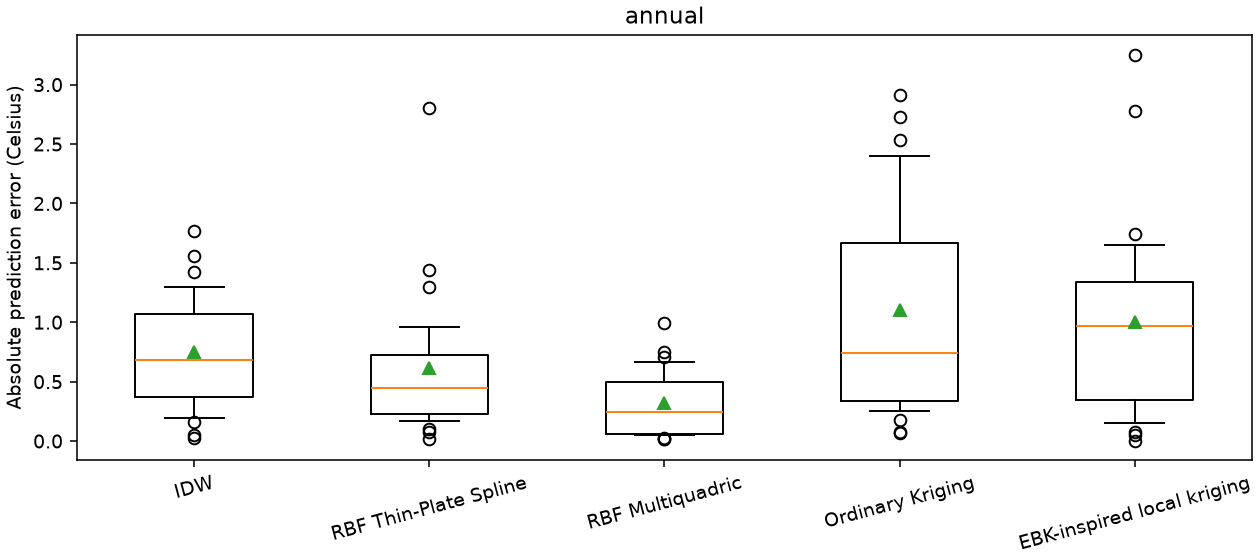

In [7]:
from IPython.display import Image, display
display(Image(filename=str(experiment.ROOT / cfg['figures_dir'] / 'error_analysis' / 'annual.png')))

## 12. Entropy-weighted TOPSIS

Oriented min–max normalization accommodates negative NSE. Constant criteria have zero weight and 0 log 0 = 0. Historical, primary and reduced criterion sets expose ranking sensitivity; entropy does not remove metric redundancy.

In [8]:
ranking.pivot(index=['period','method'], columns='configuration', values='rank')

configuration                      historical  primary  reduced
period method                                                  
annual EBK-inspired local kriging         4.0      5.0      5.0
       IDW                                3.0      3.0      3.0
       Ordinary Kriging                   5.0      4.0      4.0
       RBF Multiquadric                   1.0      1.0      1.0
       RBF Thin-Plate Spline              2.0      2.0      2.0
fall   EBK-inspired local kriging         5.0      5.0      5.0
       IDW                                3.0      3.0      3.0
       Ordinary Kriging                   4.0      4.0      4.0
       RBF Multiquadric                   1.0      1.0      1.0
       RBF Thin-Plate Spline              2.0      2.0      2.0
spring EBK-inspired local kriging         3.0      4.0      5.0
       IDW                                5.0      5.0      4.0
       Ordinary Kriging                   4.0      3.0      3.0
       RBF Multiquadric                   1.0      1.0      1.0
       RBF Thin-Plate Spline              2.0      2.0      2.0
summer EBK-inspired local kriging         5.0      5.0      5.0
       IDW                                3.0      3.0      3.0
       Ordinary Kriging                   4.0      4.0      4.0
       RBF Multiquadric                   1.0      1.0      1.0
       RBF Thin-Plate Spline              2.0      2.0      2.0
winter EBK-inspired local kriging         4.0      5.0      5.0
       IDW                                1.0      2.0      2.0
       Ordinary Kriging                   5.0      4.0      4.0
       RBF Multiquadric                   2.0      1.0      1.0
       RBF Thin-Plate Spline              3.0      3.0      3.0

## 13. Results and limitations

Annual Multiquadric RBF MAE is about 0.323 °C. Winter IDW and Multiquadric RBF MAEs are nearly tied; criterion selection changes the TOPSIS winner. Small spatial sample, reanalysis smoothing, spatial dependence, fixed variograms/lapse rate, normal-score clipping, short unconverged pseudo-target chains and exclusive elevation use by IDW limit conclusions. All six SRTM GL1 tiles were acquired on 27 November 2026 through OpenTopography; the documented replacement and five-method maps are complete. Historical-to-replacement IDW map RMSE is 0.05724 °C; verified evaluation is unchanged. Original software is MIT-licensed; third-party data permissions remain separate. Consult the report for the full scientific interpretation.

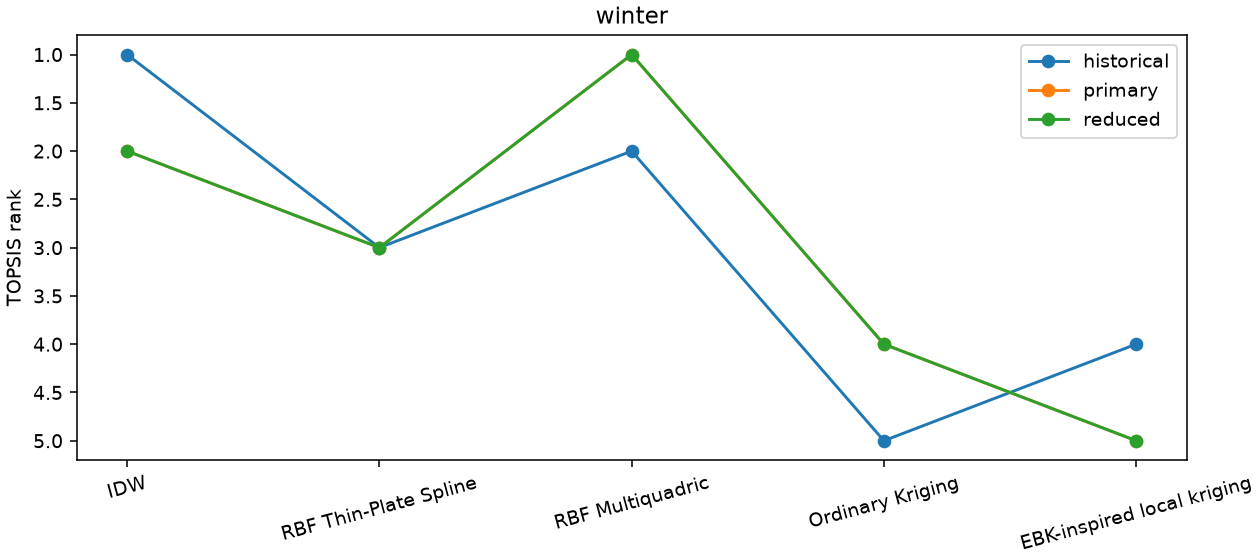

In [9]:
display(Image(filename=str(experiment.ROOT / cfg['figures_dir'] / 'rankings' / 'winter.png')))